# Week 07. Lets do it

### What is an ensemble model? 
These models conduct ensemble learning. They combine the predictions of multiple models to make a final prediction.
### Types of ensemble learning:
#### Bagging: trains multiple instances of the same model in parallel on different subsets of data. Reduces variance and prevents overfitting. ex Random Forest
#### Boosting: Trains different homogenous models sequentially, aiming to correct errors in the previous model. ex XGBoost, AdaBoost, GBM 
#### Stacking/Blending: Combines the predictions of multiple heterogenous (different) models to make a final prediction using a meta-learning model. 

In [1]:
import pandas as pd
data = pd.read_csv("../data/covtype.csv")
# data = pd.read_csv("../data/cov_small.csv")
print(data.head())
print(len(data))

   Elevation  Aspect  Slope  Horizontal_Distance_To_Hydrology  \
0       2596      51      3                               258   
1       2590      56      2                               212   
2       2804     139      9                               268   
3       2785     155     18                               242   
4       2595      45      2                               153   

   Vertical_Distance_To_Hydrology  Horizontal_Distance_To_Roadways  \
0                               0                              510   
1                              -6                              390   
2                              65                             3180   
3                             118                             3090   
4                              -1                              391   

   Hillshade_9am  Hillshade_Noon  Hillshade_3pm  \
0            221             232            148   
1            220             235            151   
2            234             238   

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

X = data.drop('Cover_Type', axis=1)
# xgboost needs class labels to start at 0, Cover_Type is 1-7 so shift it down to 0-6
y = data['Cover_Type'] - 1
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

### Boosting models we will create and test
## AdaBoost:
 reweighs misclassified data in each iteration. I will use the **decision tree** classifier because it is the most commonly used classifier.

## Gradient Boost:
 optimizs loss using gradient descent, fitting weak learners to the residuals (error) of previous models. Lacks regularization.
## XGBoost: 
extreme gradient boost. Incorporates L1 and L2 regularization, supports parrallel processing, amd uses second order gradient optimization.

### Boosting models
Each function builds a boosting model and fits it on the training data. Tree based models are not affected by feature scaling, so no StandardScaler is needed here.

In [3]:
def gradient_boost(X_train, y_train, n_estimators=100, learning_rate=0.1, max_depth=3):
    # each new tree is fit on the gradient of the loss (the residual errors) of the trees before it
    model = GradientBoostingClassifier(n_estimators=n_estimators, learning_rate=learning_rate,
                                       max_depth=max_depth)
    model.fit(X_train, y_train)
    return model


def ada_boost(X_train, y_train, n_estimators=100, learning_rate=1.0, max_depth=1):
    # reweights the samples after each tree so the next tree focuses on the ones that were misclassified
    model = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=max_depth),
                               n_estimators=n_estimators, learning_rate=learning_rate)
    model.fit(X_train, y_train)
    return model


def xg_boost(X_train, y_train, n_estimators=100, learning_rate=0.1, max_depth=6):
    # gradient boosting with regularization and a fast histogram based tree method
    model = XGBClassifier(n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth,
                          tree_method='hist', n_jobs=-1)
    model.fit(X_train, y_train)
    return model

In [5]:
# note: sklearn's GradientBoostingClassifier is single threaded and builds 7 trees (one per class) each round, so this one is slow on ~465k rows
gb_model = gradient_boost(X_train, y_train)
ada_model = ada_boost(X_train, y_train)
xgb_model = xg_boost(X_train, y_train)

In [ ]:
for name, model in [("Gradient Boost", gb_model), ("AdaBoost", ada_model), ("XGBoost", xgb_model)]:
    print(f"{name} train accuracy: {model.score(X_train, y_train):.4f}  test accuracy: {model.score(X_test, y_test):.4f}")

## Comparing the models on a subset
The full dataset is ~581k rows, which is too slow for grid searching (especially sklearn's gradient boost). I take a stratified 25k row subset so the class balance stays the same, then hold out 20% of it as a test set that is never touched during tuning.

For each model I vary two parameters with `GridSearchCV` (3 fold CV, `return_train_score=True`), which gives me for every combination:
- **fit time**
- **train accuracy** and **CV accuracy**
- **bias/variance**: a low train accuracy means high bias (underfitting). A big gap between train and CV accuracy means high variance (overfitting).

In [13]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# stratified subset of the full data
data_sub, _ = train_test_split(data, train_size=25000, stratify=data['Cover_Type'])
X_sub = data_sub.drop('Cover_Type', axis=1)
y_sub = data_sub['Cover_Type'] - 1
Xs_train, Xs_test, ys_train, ys_test = train_test_split(X_sub, y_sub, test_size=0.2, stratify=y_sub)
print("subset train:", Xs_train.shape, " subset test:", Xs_test.shape)

cv = StratifiedKFold(n_splits=3, shuffle=True)

subset train: (20000, 54)  subset test: (5000, 54)


In [7]:
def run_grid(model, param_grid, n_jobs=-1):
    # grid search with CV and return a tidy table of fit time, train/cv accuracy and the gap between them
    start = time.time()
    grid = GridSearchCV(model, param_grid, cv=cv, scoring='accuracy', return_train_score=True, n_jobs=n_jobs)
    grid.fit(Xs_train, ys_train)
    print(f"grid search took {time.time() - start:.1f}s")

    res = pd.DataFrame(grid.cv_results_)
    table = res[['params', 'mean_fit_time', 'mean_train_score', 'mean_test_score', 'std_test_score']].copy()
    for name in param_grid:
        table[name] = res['param_' + name]
    table = table.rename(columns={'mean_fit_time': 'fit_time_s', 'mean_train_score': 'train_acc',
                                  'mean_test_score': 'cv_acc', 'std_test_score': 'cv_std'})
    table['gap'] = table['train_acc'] - table['cv_acc']
    table['diagnosis'] = table.apply(lambda r: diagnose(r, table['cv_acc'].max()), axis=1)
    return grid, table.drop(columns='params')


def diagnose(row, best_cv):
    # rough rule of thumb for bias/variance
    if row['gap'] > 0.05:
        return 'overfit (high variance)'
    if row['cv_acc'] < best_cv - 0.03:
        return 'underfit (high bias)'
    return 'good fit'


# colors for the plots
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']

def plot_grid(table, x_param, line_param, title):
    # left: train (dashed) vs cv (solid) accuracy, right: fit time. one line per value of line_param
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    for color, (val, grp) in zip(COLORS, table.groupby(line_param)):
        grp = grp.sort_values(x_param)
        ax1.plot(grp[x_param], grp['train_acc'], '--', color=color, linewidth=2, marker='o', markersize=5)
        ax1.plot(grp[x_param], grp['cv_acc'], '-', color=color, linewidth=2, marker='o', markersize=5,
                 label=f'{line_param}={val}')
        ax2.plot(grp[x_param], grp['fit_time_s'], '-', color=color, linewidth=2, marker='o', markersize=5,
                 label=f'{line_param}={val}')
    ax1.set_title(f'{title}: accuracy (solid = CV, dashed = train)')
    ax1.set_xlabel(x_param); ax1.set_ylabel('accuracy')
    ax2.set_title(f'{title}: fit time per fold')
    ax2.set_xlabel(x_param); ax2.set_ylabel('seconds')
    for ax in (ax1, ax2):
        ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()

### Gradient Boost: vary `n_estimators` and `max_depth`
Both control model complexity: more trees and deeper trees fit the training data more closely.

grid search took 178.7s
 fit_time_s  train_acc  cv_acc  cv_std  n_estimators  max_depth    gap               diagnosis
     9.4803     0.7406  0.7240  0.0042            50          2 0.0166    underfit (high bias)
    20.4665     0.7595  0.7396  0.0027           100          2 0.0199    underfit (high bias)
    37.5018     0.7814  0.7490  0.0025           200          2 0.0324    underfit (high bias)
    14.7784     0.7740  0.7467  0.0041            50          3 0.0273    underfit (high bias)
    29.1161     0.8019  0.7560  0.0038           100          3 0.0459    underfit (high bias)
    50.7721     0.8384  0.7717  0.0043           200          3 0.0667 overfit (high variance)
    24.0791     0.8561  0.7796  0.0027            50          5 0.0765 overfit (high variance)
    43.5385     0.9000  0.7933  0.0024           100          5 0.1067 overfit (high variance)
    72.3771     0.9486  0.8029  0.0042           200          5 0.1457 overfit (high variance)
best: {'max_depth': 5, 'n_

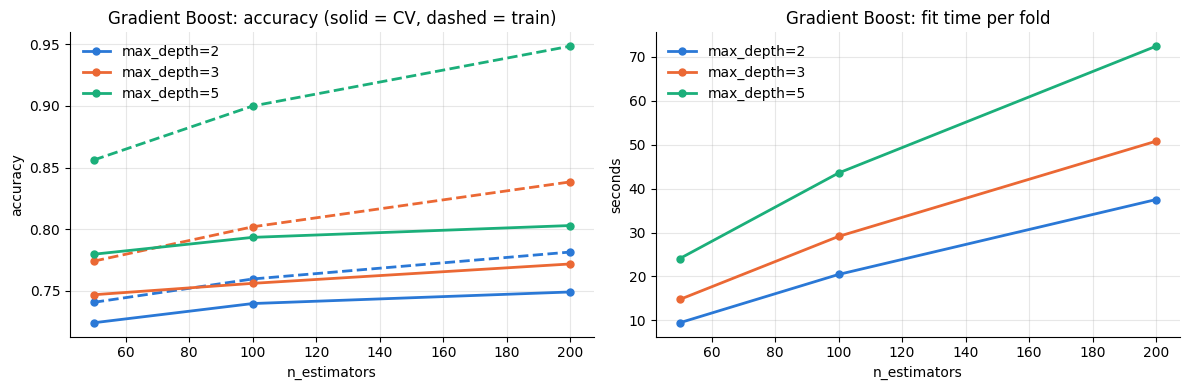

In [17]:
gb_grid, gb_table = run_grid(GradientBoostingClassifier(),
                             {'n_estimators': [50, 100, 200], 'max_depth': [2, 3, 5]})
print(gb_table.round(4).to_string(index=False))
print("best:", gb_grid.best_params_, "cv acc:", round(gb_grid.best_score_, 4))
plot_grid(gb_table, 'n_estimators', 'max_depth', 'Gradient Boost')

### AdaBoost: vary `n_estimators` and the depth of the base tree
AdaBoost usually uses stumps (depth 1). Deeper base trees make each weak learner stronger.

grid search took 174.1s
 fit_time_s  train_acc  cv_acc  cv_std  n_estimators  estimator__max_depth     gap               diagnosis
     1.8326     0.6280  0.6291  0.0142            50                     1 -0.0011    underfit (high bias)
     3.6599     0.6142  0.6146  0.0205           100                     1 -0.0004    underfit (high bias)
     7.2563     0.5988  0.5974  0.0145           200                     1  0.0014    underfit (high bias)
    14.4125     0.5759  0.5747  0.0264           400                     1  0.0012    underfit (high bias)
     3.0034     0.5934  0.5901  0.0297            50                     2  0.0033    underfit (high bias)
     5.8743     0.5855  0.5755  0.0329           100                     2  0.0099    underfit (high bias)
    11.8932     0.5796  0.5705  0.0081           200                     2  0.0091    underfit (high bias)
    23.5308     0.5512  0.5421  0.0091           400                     2  0.0092    underfit (high bias)
     5.1789  

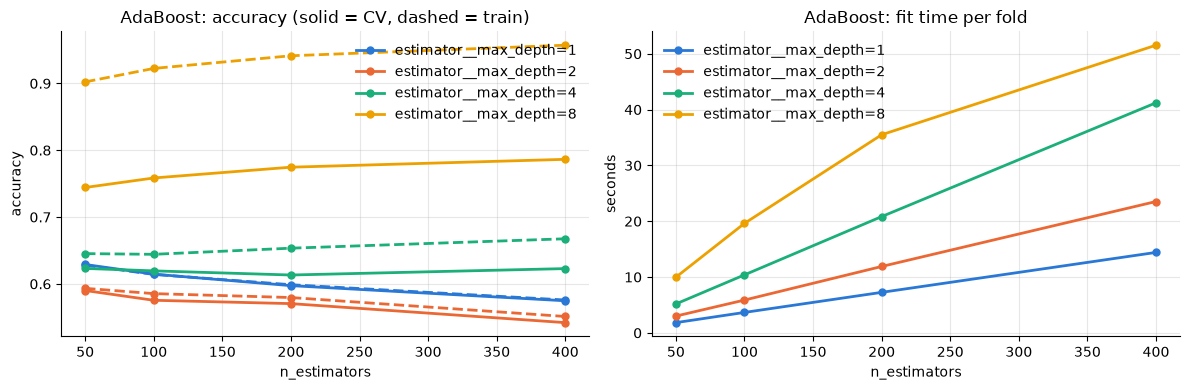

In [ ]:
ada_grid, ada_table = run_grid(AdaBoostClassifier(estimator=DecisionTreeClassifier()),
                               {'n_estimators': [50, 100, 200, 400], 'estimator__max_depth': [1, 2, 4, 8]})
print(ada_table.round(4).to_string(index=False))
print("best:", ada_grid.best_params_, "cv acc:", round(ada_grid.best_score_, 4))
plot_grid(ada_table, 'n_estimators', 'estimator__max_depth', 'AdaBoost')

### XGBoost: vary `max_depth` and `learning_rate`
200 trees, `n_jobs=-1` on the grid search because xgboost already uses all the cores.

grid search took 95.9s
 fit_time_s  train_acc  cv_acc  cv_std  max_depth  learning_rate    gap               diagnosis
     1.1921     0.7236  0.7134  0.0037          2           0.03 0.0101    underfit (high bias)
     1.6478     0.7705  0.7453  0.0020          4           0.03 0.0252    underfit (high bias)
     2.4835     0.8319  0.7734  0.0017          6           0.03 0.0585 overfit (high variance)
     4.6880     0.9479  0.8180  0.0052         10           0.03 0.1300 overfit (high variance)
     1.0978     0.7559  0.7379  0.0022          2           0.10 0.0180    underfit (high bias)
     1.6342     0.8353  0.7762  0.0027          4           0.10 0.0591 overfit (high variance)
     2.2935     0.9152  0.8065  0.0003          6           0.10 0.1087 overfit (high variance)
     4.0500     0.9974  0.8380  0.0033         10           0.10 0.1595 overfit (high variance)
     1.0696     0.7993  0.7589  0.0011          2           0.30 0.0405    underfit (high bias)
     1.7381     0

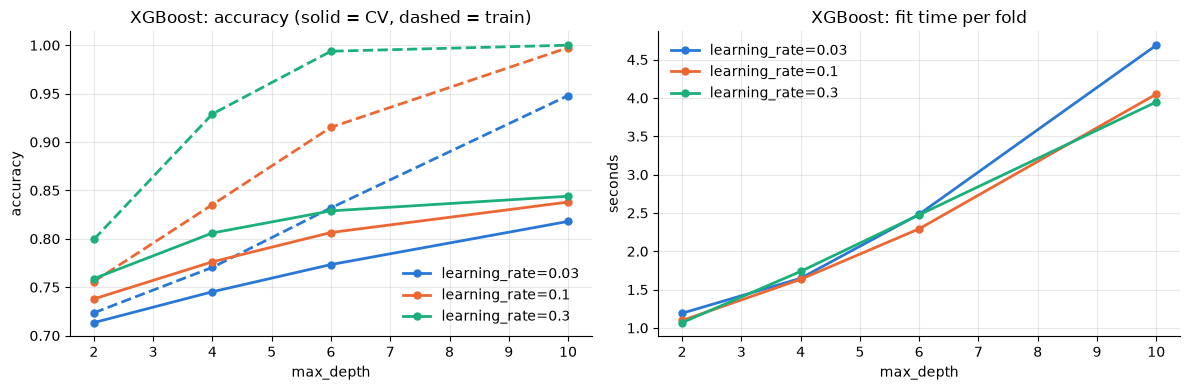

In [ ]:
xgb_grid, xgb_table = run_grid(XGBClassifier(n_estimators=200, tree_method='hist', n_jobs=-1),
                               {'max_depth': [2, 4, 6, 10], 'learning_rate': [0.03, 0.1, 0.3]}, n_jobs=1)
print(xgb_table.round(4).to_string(index=False))
print("best:", xgb_grid.best_params_, "cv acc:", round(xgb_grid.best_score_, 4))
plot_grid(xgb_table, 'max_depth', 'learning_rate', 'XGBoost')

### Final comparison with the tuned parameters
Refit each model with its best CV parameters on the whole subset training set (using the functions from above), time it, and score on the held-out subset test set.

In [ ]:
tuned = {
    'Gradient Boost': (gradient_boost, gb_grid.best_params_),
    'AdaBoost': (ada_boost, {'n_estimators': ada_grid.best_params_['n_estimators'],
                             'max_depth': ada_grid.best_params_['estimator__max_depth']}),
    'XGBoost': (xg_boost, {**xgb_grid.best_params_, 'n_estimators': 200}),
}
cv_scores = {'Gradient Boost': gb_grid.best_score_, 'AdaBoost': ada_grid.best_score_, 'XGBoost': xgb_grid.best_score_}

rows = []
for name, (fn, params) in tuned.items():
    start = time.time()
    model = fn(Xs_train, ys_train, **params)
    fit_time = time.time() - start
    train_acc = model.score(Xs_train, ys_train)
    test_acc = model.score(Xs_test, ys_test)
    rows.append({'model': name, 'params': params, 'fit_time_s': fit_time, 'train_acc': train_acc,
                 'cv_acc': cv_scores[name], 'test_acc': test_acc, 'gap (train - test)': train_acc - test_acc})

summary = pd.DataFrame(rows)
print(summary.round(4).to_string(index=False))

         model                                                       params  fit_time_s  train_acc  cv_acc  test_acc  gap (train - test)
Gradient Boost                        {'max_depth': 5, 'n_estimators': 200}     89.3618     0.9338  0.8113    0.8298              0.1040
      AdaBoost                        {'n_estimators': 400, 'max_depth': 8}     43.6060     0.9229  0.7864    0.7892              0.1337
       XGBoost {'learning_rate': 0.3, 'max_depth': 10, 'n_estimators': 200}      5.3856     1.0000  0.8440    0.8674              0.1326


### Results: time, accuracy and bias/variance

**Training time.** XGBoost is by far the fastest: about 5s for the tuned model, against about 44s for AdaBoost and about 89s for Gradient Boost. It builds trees with histograms and uses every core, while sklearn's gradient boost is single threaded and builds 7 trees per round (one per class). For every model, fit time grows roughly linearly with `n_estimators` and with tree depth. (The per-fold times in the grid tables were measured while several fits shared the CPU, so they are inflated. The final table times one fit at a time.)

**Accuracy (held-out subset test set).** XGBoost **0.867**, Gradient Boost **0.830**, AdaBoost **0.789**.

**Bias/variance.**
- **Gradient Boost:** shallow trees (depth 2) underfit. Train and CV accuracy are both low (~0.74-0.79) with a small gap, so this is high bias. Going to depth 5 or 200 trees raises train accuracy much faster than CV accuracy, and the gap grows to 0.14, so variance goes up. But CV accuracy still rises, so the extra complexity is still worth it at this data size.
- **AdaBoost:** with stumps (depth 1), the classic AdaBoost setup, it is badly underfit (~0.63 for train and CV, no gap). Adding trees makes it *worse*, because the 7-class problem is too hard for stumps to combine well. Depth 2-4 base trees don't help much. Only depth 8 trees push it to 0.79 CV, and then the train/CV gap jumps to ~0.17 (high variance). AdaBoost has no setting here that is both accurate and low variance.
- **XGBoost:** a low learning rate with shallow trees underfits (0.71 CV). A higher learning rate and deeper trees both increase variance: at depth 10 and lr 0.3 it hits 100% train accuracy, a clear sign of memorizing the data. Even so, CV accuracy keeps climbing (0.844), so the best CV model is also the most "overfit" one by the gap.

**Takeaway.** On a 20k-row training set, the models that score best on CV all have a large train/CV gap. The gap shows that variance is high, but cutting complexity to close it raises bias more than it lowers variance. With more data (the full 581k rows), the gap would likely shrink and deeper models would hold up even better. Of the three, XGBoost gives the best accuracy at a tiny fraction of the training time.

### Stacking model plan: Random Forest, Logistic Regression, KNN, SVM, MLP

## Stacking classifier
Stacking trains several different (heterogeneous) base learners, then trains a **meta learner** on their predictions. `StackingClassifier` makes the meta learner's training data with internal cross validation (`cv=5`): each base learner predicts on folds it was not trained on, so the meta learner sees honest out-of-fold predictions instead of memorized ones.

Same 20k-row subset training set as the boosting section, so the times stay reasonable. Unlike the tree models, logistic regression, KNN, SVM and the MLP all depend on feature scale (distances, gradients and kernels), so each one is a `StandardScaler` + model pipeline. The scaler is fit inside every CV fold, so no information leaks from the validation folds.

### Step 1: tune each base learner
Each base learner gets its own grid search (same `run_grid` helper and 3-fold CV as above). The `best_estimator_` from each grid is the version that goes into the stack.

In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
import time
base_grids = {
    # more trees lowers variance, max_features controls how different the trees are from each other
    'rf': (RandomForestClassifier(n_jobs=1),
           {'n_estimators': [100, 300], 'max_features': ['sqrt', 0.3, 0.5]}),
    # C is the inverse of the regularization strength
    'lr': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
           {'logisticregression__C': [0.01, 0.1, 1, 10, 100], 'logisticregression__class_weight': [None, 'balanced']}),
    # small k = low bias / high variance, distance weighting lets close neighbors count more
    'knn': (make_pipeline(StandardScaler(), KNeighborsClassifier()),
            {'kneighborsclassifier__n_neighbors': [1, 3, 5, 9, 15], 'kneighborsclassifier__weights': ['uniform', 'distance']}),
    # rbf kernel: C trades margin width for training errors, gamma sets how local each support vector is
    'svm': (make_pipeline(StandardScaler(), SVC(kernel='rbf')),
            {'svc__C': [1, 10, 100], 'svc__gamma': ['scale', 0.1, 0.5]}),
    # network size and L2 penalty (alpha), early stopping holds out 10% to stop before overfitting
    'mlp': (make_pipeline(StandardScaler(), MLPClassifier(max_iter=1000, early_stopping=True)),
            {'mlpclassifier__hidden_layer_sizes': [(50,), (100,), (100, 50)], 'mlpclassifier__alpha': [1e-4, 1e-3, 1e-2]}),
}

base_best = {}
for name, (model, grid_params) in base_grids.items():
    print(f"===== {name} =====")
    grid, table = run_grid(model, grid_params)
    print(table.round(4).to_string(index=False))
    print("best:", grid.best_params_, "cv acc:", round(grid.best_score_, 4), "\n")
    base_best[name] = grid.best_estimator_

===== rf =====
grid search took 55.2s
 fit_time_s  train_acc  cv_acc  cv_std  n_estimators max_features    gap               diagnosis
     3.2908        1.0  0.8221  0.0070           100         sqrt 0.1779 overfit (high variance)
     9.4979        1.0  0.8240  0.0059           300         sqrt 0.1760 overfit (high variance)
     5.6349        1.0  0.8294  0.0048           100          0.3 0.1706 overfit (high variance)
    14.6960        1.0  0.8299  0.0044           300          0.3 0.1701 overfit (high variance)
     8.2452        1.0  0.8281  0.0067           100          0.5 0.1719 overfit (high variance)
    20.9148        1.0  0.8328  0.0051           300          0.5 0.1672 overfit (high variance)
best: {'max_features': 0.5, 'n_estimators': 300} cv acc: 0.8328 

===== lr =====
grid search took 8.3s
 fit_time_s  train_acc  cv_acc  cv_std  logisticregression__C logisticregression__class_weight     gap            diagnosis
     0.4218     0.7131  0.7067  0.0048                  

### Step 2: tune the meta learners inside the stacking pipeline
Two stacks with the same tuned base learners, each with a different meta learner:
- **Logistic regression:** tune `C` (regularization strength) and `passthrough` (whether the meta learner also sees the original features next to the base learner predictions).
- **Linear regression:** `LinearRegression` is a regressor, so `StackingClassifier` won't accept it as a final estimator. `RidgeClassifier` is the classification version of linear regression: it fits a least-squares linear regression to the one-hot (Â±1) class targets and predicts the class with the highest output. With `alpha` near 0 it is plain ordinary least squares linear regression, and larger `alpha` adds an L2 penalty. That matters here because the base learner probabilities are highly correlated (and each set sums to 1), which makes unpenalized least squares unstable. Tune `alpha` and `passthrough`.

Both meta learners are a `StandardScaler` + model pipeline. When `passthrough=True` the raw features are on very different scales (elevation in meters next to 0/1 soil columns), and without scaling the meta learner does much worse.

The grid search wraps the **whole** `StackingClassifier`, with `final_estimator__...` parameters, so every candidate refits the base learners and rebuilds the out-of-fold predictions. The meta learner is never tuned on predictions the base learners made on their own training data.

In [ ]:
base_estimators = list(base_best.items())

# the meta learners get a scaler too: with passthrough=True they also see the raw (unscaled) features
meta_grids = {
    'stack_logreg': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
                     {'final_estimator__logisticregression__C': [0.01, 0.1, 1, 10], 'passthrough': [False, True]}),
    'stack_linreg': (make_pipeline(StandardScaler(), RidgeClassifier()),
                     {'final_estimator__ridgeclassifier__alpha': [1e-3, 1, 10, 100], 'passthrough': [False, True]}),
}

stack_best = {}
for name, (meta, grid_params) in meta_grids.items():
    print(f"===== {name} =====")
    stack = StackingClassifier(estimators=base_estimators, final_estimator=meta, cv=5)
    grid, table = run_grid(stack, grid_params)
    print(table.round(4).to_string(index=False))
    print("best:", grid.best_params_, "cv acc:", round(grid.best_score_, 4), "\n")
    stack_best[name] = grid.best_estimator_

### Step 3: compare the cross validated performance
Every tuned model (the five base learners and the two stacks) is scored with repeated stratified 10-fold CV (3 repeats = 30 accuracy scores per model) on the subset training set. The boxplots show the spread of those 30 scores: the orange line is the median and the green triangle is the mean.

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

def evaluate_model(model, X, y):
    # 10 fold CV repeated 3 times, returns all 30 accuracy scores
    rcv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3)
    return cross_val_score(model, X, y, scoring='accuracy', cv=rcv, n_jobs=-1)

models = {**base_best, **stack_best}
results, names = [], []
for name, model in models.items():
    start = time.time()
    scores = evaluate_model(model, Xs_train, ys_train)
    results.append(scores)
    names.append(name)
    print('>%s %.3f (%.3f)  [%.0fs]' % (name, np.mean(scores), np.std(scores), time.time() - start))

# plot model performance for comparison
plt.figure(figsize=(10, 5))
plt.boxplot(results, tick_labels=names, showmeans=True)
plt.ylabel('accuracy')
plt.title('Repeated 10-fold CV accuracy')
plt.show()

In [ ]:
# final check on the held-out subset test set, which was never used for tuning
for name, model in models.items():
    model.fit(Xs_train, ys_train)
    print(f"{name:13s} test accuracy: {model.score(Xs_test, ys_test):.4f}")

### Stacking results
(Numbers are from one run. The subset and CV splits are random, so they move a little each time.)

**Tuned base learners.** Random forest is the strongest single model (~0.84 CV), followed by SVM (~0.81), KNN (~0.80) and the MLP (~0.79). Logistic regression is far behind (~0.72), because the classes are not linearly separable in the raw features.

**Meta learners.** Both stacks reach ~0.855 mean CV accuracy (~0.87 on the held-out subset test set), about 1 point above the random forest alone. Logistic regression and linear regression (ridge) as meta learners finish almost tied. The base learner predictions already separate the classes well, so the meta learner only has to learn a fairly simple weighting, and both linear models can do that. The meta learner hyperparameters (`C` / `alpha`) barely matter (all within ~0.005). `passthrough=True` helps slightly once the features are scaled.

**Cost.** The stacks are much slower: every stack fit trains all 5 base learners 6 times (5 internal CV folds + 1 final fit), and the SVM dominates that time. Tuning plus the 30-fold evaluation for the two stacks takes roughly 40 minutes on this machine.